# Phase 6.2 — Fraud Detection Exploratory Data Analysis (EDA)

## Banking Risk Intelligence Platform

### 1. Project Objective and Business Context
In retail and commercial banking, transaction fraud constitutes an asymmetric risk:
- **Severe Class Imbalance**: Fraudulent events occur in a tiny fraction of total transaction volume (< 0.2%).
- **Financial and Operational Impact**: Missed frauds (False Negatives) result in direct financial write-offs, chargeback losses, regulatory scrutiny, and customer churn. Conversely, false fraud flags (False Positives) induce customer friction (declined legitimate transactions, false card freezes) and escalate operational manual review costs.
- **Asymmetric Loss Function**: Accuracy is mathematically inappropriate for evaluating fraud models (a naive model predicting all transactions as legitimate achieves 99.83% accuracy while failing completely at risk mitigation). PR-AUC (Precision-Recall Area Under Curve), precision, recall, and cost-weighted loss matrices are the mandatory evaluation metrics.

### Objective of Phase 6.2
This notebook conducts a rigorous, comprehensive Exploratory Data Analysis on the benchmark European credit card transaction dataset (`data/raw/creditcard.csv`). 
Specifically, we analyze:
1. Data hygiene, missingness, and structural duplicate records.
2. The extreme class imbalance profile before and after deduplication.
3. Transaction amount distributions, log transforms, and outlier profiles across classes.
4. Temporal characteristics (seconds elapsed) across 48 hours and risk patterns across 8 discrete time windows.
5. Zero-amount transaction patterns (card testing / micro-authorizations).
6. Non-parametric distributional divergence for PCA features $V_1$ through $V_{28}$ using Mann–Whitney $U$ tests.
7. Multiplicity correction via the Benjamini–Hochberg False Discovery Rate (FDR) procedure.
8. Bivariate and pairwise linear and rank correlation structures.

### 2. Environment Setup and Data Loading
We load necessary analytical and visualization libraries. Reproducibility is anchored via a fixed random seed.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Dataset path
DATA_PATH = Path('../data/raw/creditcard.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('data/raw/creditcard.csv')

print(f"Loading dataset from: {DATA_PATH.resolve()}")
df_raw = pd.read_csv(DATA_PATH)
print(f"Raw dataset successfully loaded. Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Loading dataset from: C:\Users\Admin\banking-risk-intelligence-platform\data\raw\creditcard.csv


Raw dataset successfully loaded. Shape: 284,807 rows x 31 columns


### 3. Data Types, Shape, and Missing-Value Analysis
We inspect the schema, column data types, memory consumption, and verify whether any missing values exist in the raw ingestion pipeline.

In [2]:
# Schema and data types summary
inspection_df = pd.DataFrame({
    'Column': df_raw.columns,
    'DataType': df_raw.dtypes.values,
    'NullCount': df_raw.isnull().sum().values,
    'NullPct': (df_raw.isnull().sum().values / len(df_raw)) * 100,
    'UniqueCount': df_raw.nunique().values
})

print(f"Total columns: {len(inspection_df)}")
print(f"Total null cells across entire table: {df_raw.isnull().sum().sum()}")
display(inspection_df.head(10))
display(inspection_df.tail(6))

Total columns: 31
Total null cells across entire table: 0


,Column,DataType,NullCount,NullPct,UniqueCount
0,Time,float64,0,0.0,124592
1,V1,float64,0,0.0,275663
2,V2,float64,0,0.0,275663
3,V3,float64,0,0.0,275663
4,V4,float64,0,0.0,275663
5,V5,float64,0,0.0,275663
6,V6,float64,0,0.0,275663
7,V7,float64,0,0.0,275663
8,V8,float64,0,0.0,275663
9,V9,float64,0,0.0,275663


,Column,DataType,NullCount,NullPct,UniqueCount
25,V25,float64,0,0.0,275663
26,V26,float64,0,0.0,275663
27,V27,float64,0,0.0,275663
28,V28,float64,0,0.0,275663
29,Amount,float64,0,0.0,32767
30,Class,int64,0,0.0,2


### 4. Duplicate Investigation and Cleaning
We evaluate duplicate rows across all 31 dimensions. In transactional streams where `Time` records elapsed seconds to high precision, exact duplicate rows across `Time`, all 28 PCA dimensions, and `Amount` represent data collection artifacts, replay anomalies, or ingestion redundancies rather than genuine identical repeat authorizations at the exact microsecond.
We investigate their class composition prior to removal.

In [3]:
duplicate_mask = df_raw.duplicated(keep='first')
n_dups_total = duplicate_mask.sum()
n_dups_legit = (duplicate_mask & (df_raw['Class'] == 0)).sum()
n_dups_fraud = (duplicate_mask & (df_raw['Class'] == 1)).sum()

print("--- Duplicate Investigation Summary ---")
print(f"Total exact duplicate rows: {n_dups_total:,}")
print(f"  - Legitimate duplicates (Class 0): {n_dups_legit:,} ({n_dups_legit/n_dups_total*100:.2f}%)")
print(f"  - Fraudulent duplicates (Class 1): {n_dups_fraud:,} ({n_dups_fraud/n_dups_total*100:.2f}%)")

# Remove exact duplicates
df = df_raw.drop_duplicates(keep='first').copy().reset_index(drop=True)
print(f"\nCleaned dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Retained records: {len(df):,} / {len(df_raw):,} ({len(df)/len(df_raw)*100:.4f}%)")

--- Duplicate Investigation Summary ---
Total exact duplicate rows: 1,081
  - Legitimate duplicates (Class 0): 1,062 (98.24%)
  - Fraudulent duplicates (Class 1): 19 (1.76%)



Cleaned dataset shape: 283,726 rows x 31 columns
Retained records: 283,726 / 284,807 (99.6204%)


### 5. Class Imbalance Analysis
We benchmark the class balance distribution before and after duplicate removal to confirm the baseline fraud prevalence.

In [4]:
# Class distributions
raw_counts = df_raw['Class'].value_counts()
clean_counts = df['Class'].value_counts()

imbalance_summary = pd.DataFrame({
    'Raw_Count': raw_counts,
    'Raw_Pct': (raw_counts / len(df_raw)) * 100,
    'Clean_Count': clean_counts,
    'Clean_Pct': (clean_counts / len(df)) * 100
}, index=[0, 1])
imbalance_summary.index = ['Legitimate (0)', 'Fraud (1)']

print("--- Class Distribution Comparison ---")
display(imbalance_summary.style.format({'Raw_Count': '{:,}', 'Clean_Count': '{:,}', 'Raw_Pct': '{:.4f}%', 'Clean_Pct': '{:.4f}%'}))

print(f"Cleaned Fraud Prevalence: {clean_counts[1] / len(df) * 100:.4f}% (1 fraud per {clean_counts[0]/clean_counts[1]:.1f} legitimate transactions)")

--- Class Distribution Comparison ---


,Raw_Count,Raw_Pct,Clean_Count,Clean_Pct
Legitimate (0),"284,315",99.8273%,"283,253",99.8333%
Fraud (1),492,0.1727%,473,0.1667%


Cleaned Fraud Prevalence: 0.1667% (1 fraud per 598.8 legitimate transactions)


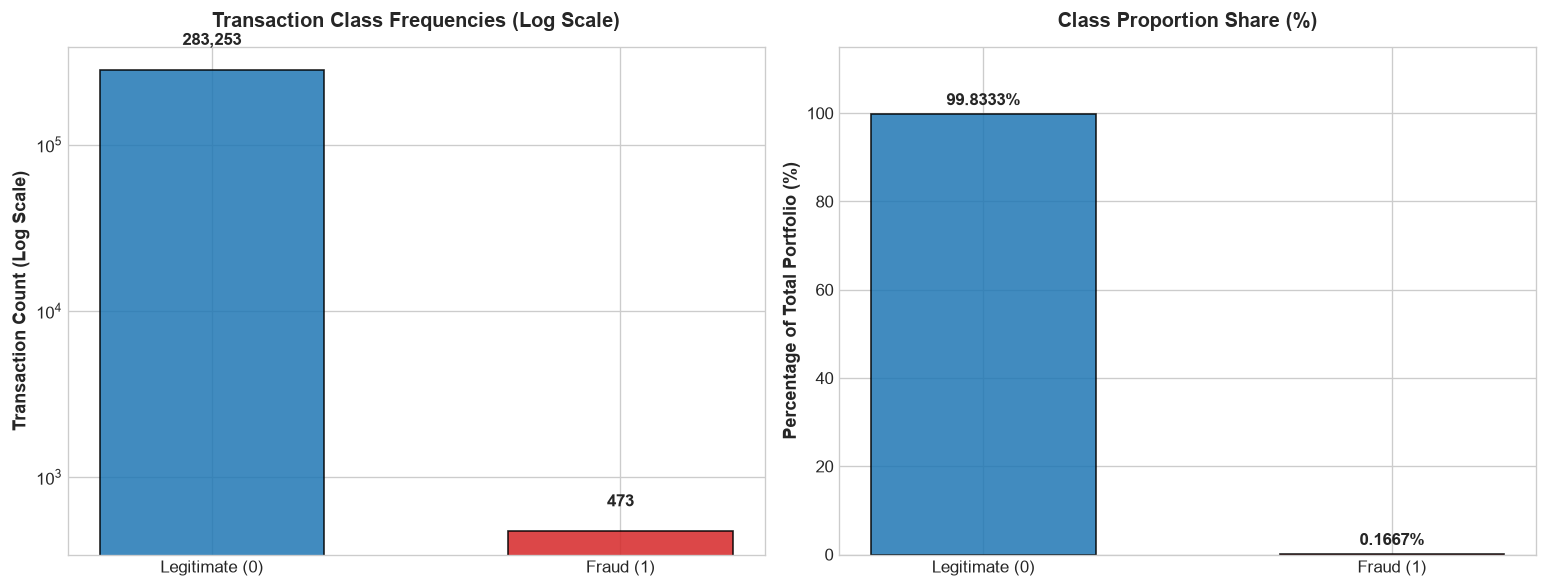

In [5]:
# Visualization: Class Distribution and Proportion
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Absolute count on log scale
bars = axes[0].bar(['Legitimate (0)', 'Fraud (1)'], clean_counts.values, color=['#1f77b4', '#d62728'], width=0.55, edgecolor='black', alpha=0.85)
axes[0].set_yscale('log')
axes[0].set_ylabel('Transaction Count (Log Scale)', fontsize=11, fontweight='bold')
axes[0].set_title('Transaction Class Frequencies (Log Scale)', fontsize=12, fontweight='bold', pad=12)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval * 1.35, f"{int(yval):,}", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Subplot 2: Percentage share breakdown
percentages = [clean_counts[0] / len(df) * 100, clean_counts[1] / len(df) * 100]
bars_pct = axes[1].bar(['Legitimate (0)', 'Fraud (1)'], percentages, color=['#1f77b4', '#d62728'], width=0.55, edgecolor='black', alpha=0.85)
axes[1].set_ylabel('Percentage of Total Portfolio (%)', fontsize=11, fontweight='bold')
axes[1].set_title('Class Proportion Share (%)', fontsize=12, fontweight='bold', pad=12)
for bar, pct in zip(bars_pct, percentages):
    axes[1].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1.2, f"{pct:.4f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_ylim(0, 115)

plt.tight_layout()
plt.show()

### 6. Transaction Amount Distribution
We analyze the summary statistics, dispersion, and quantile profiles for transaction amounts (`Amount`) partitioned by transaction legitimacy.

In [6]:
amount_legit = df[df['Class'] == 0]['Amount']
amount_fraud = df[df['Class'] == 1]['Amount']

stats_amount = pd.DataFrame({
    'Legitimate (Class 0)': [
        amount_legit.count(),
        amount_legit.mean(),
        amount_legit.std(),
        amount_legit.min(),
        amount_legit.quantile(0.25),
        amount_legit.median(),
        amount_legit.quantile(0.75),
        amount_legit.quantile(0.95),
        amount_legit.quantile(0.99),
        amount_legit.max()
    ],
    'Fraudulent (Class 1)': [
        amount_fraud.count(),
        amount_fraud.mean(),
        amount_fraud.std(),
        amount_fraud.min(),
        amount_fraud.quantile(0.25),
        amount_fraud.median(),
        amount_fraud.quantile(0.75),
        amount_fraud.quantile(0.95),
        amount_fraud.quantile(0.99),
        amount_fraud.max()
    ]
}, index=['Count', 'Mean (€)', 'Std Dev (€)', 'Min (€)', '25th Pct (€)', 'Median (€)', '75th Pct (€)', '95th Pct (€)', '99th Pct (€)', 'Max (€)'])

print("--- Transaction Amount Summary Statistics ---")
display(stats_amount.style.format({'Legitimate (Class 0)': '{:,.2f}', 'Fraudulent (Class 1)': '{:,.2f}'}))

--- Transaction Amount Summary Statistics ---


,Legitimate (Class 0),Fraudulent (Class 1)
Count,"283,253.00",473.00
Mean (€),88.41,123.87
Std Dev (€),250.38,260.21
Min (€),0.00,0.00
25th Pct (€),5.67,1.00
Median (€),22.00,9.82
75th Pct (€),77.46,105.89
95th Pct (€),365.00,655.82
99th Pct (€),"1,018.06","1,364.14"
Max (€),"25,691.16","2,125.87"


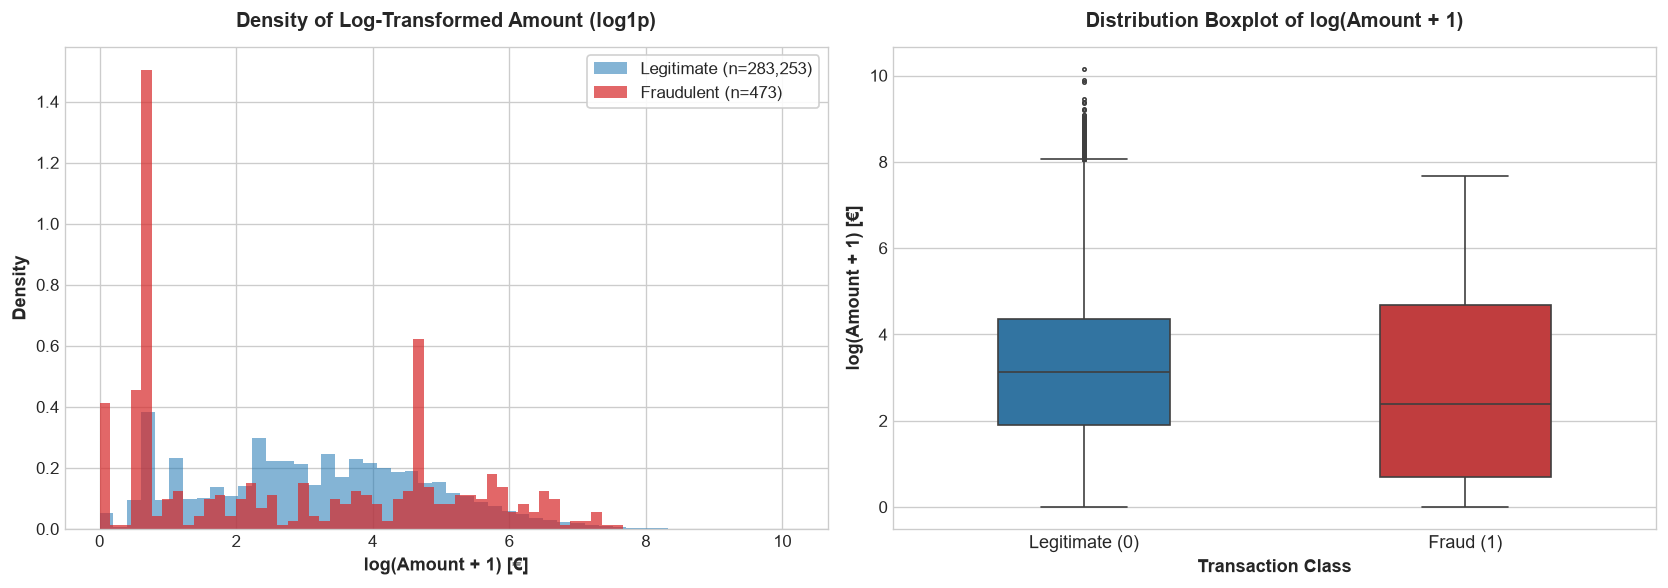

In [7]:
# Visualizations: Amount Distribution & Boxplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Histogram of log1p(Amount)
sns.histplot(np.log1p(amount_legit), bins=50, ax=axes[0], color='#1f77b4', label=f'Legitimate (n={len(amount_legit):,})', stat='density', alpha=0.55, edgecolor=None)
sns.histplot(np.log1p(amount_fraud), bins=50, ax=axes[0], color='#d62728', label=f'Fraudulent (n={len(amount_fraud):,})', stat='density', alpha=0.7, edgecolor=None)
axes[0].set_title('Density of Log-Transformed Amount (log1p)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('log(Amount + 1) [€]', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Density', fontsize=11, fontweight='bold')
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Plot 2: Boxplot comparison of log1p(Amount)
df['log_amount'] = np.log1p(df['Amount'])
sns.boxplot(x='Class', y='log_amount', data=df, ax=axes[1], palette=['#1f77b4', '#d62728'], width=0.45, fliersize=2)
axes[1].set_xticklabels(['Legitimate (0)', 'Fraud (1)'], fontsize=11)
axes[1].set_title('Distribution Boxplot of log(Amount + 1)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Transaction Class', fontsize=11, fontweight='bold')
axes[1].set_ylabel('log(Amount + 1) [€]', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Transaction Time Analysis
The `Time` feature tracks the cumulative seconds elapsed since the start of recording.
With $\max(\text{Time}) = 172,792\text{ seconds} \approx 47.998\text{ hours}$, the dataset covers approximately two 24-hour business cycles.
We examine the temporal dynamics and test whether fraud timing exhibits systematic diurnal patterns.

--- Transaction Time Summary Statistics (Seconds Elapsed) ---


,Legitimate (0),Fraudulent (1)
Min,0.0,406.0
25th Pct,"54,233.0","41,203.0"
Median,"84,711.0","73,408.0"
Mean,"94,835.1","80,450.5"
75th Pct,"139,308.0","129,095.0"
Max,"172,792.0","170,348.0"


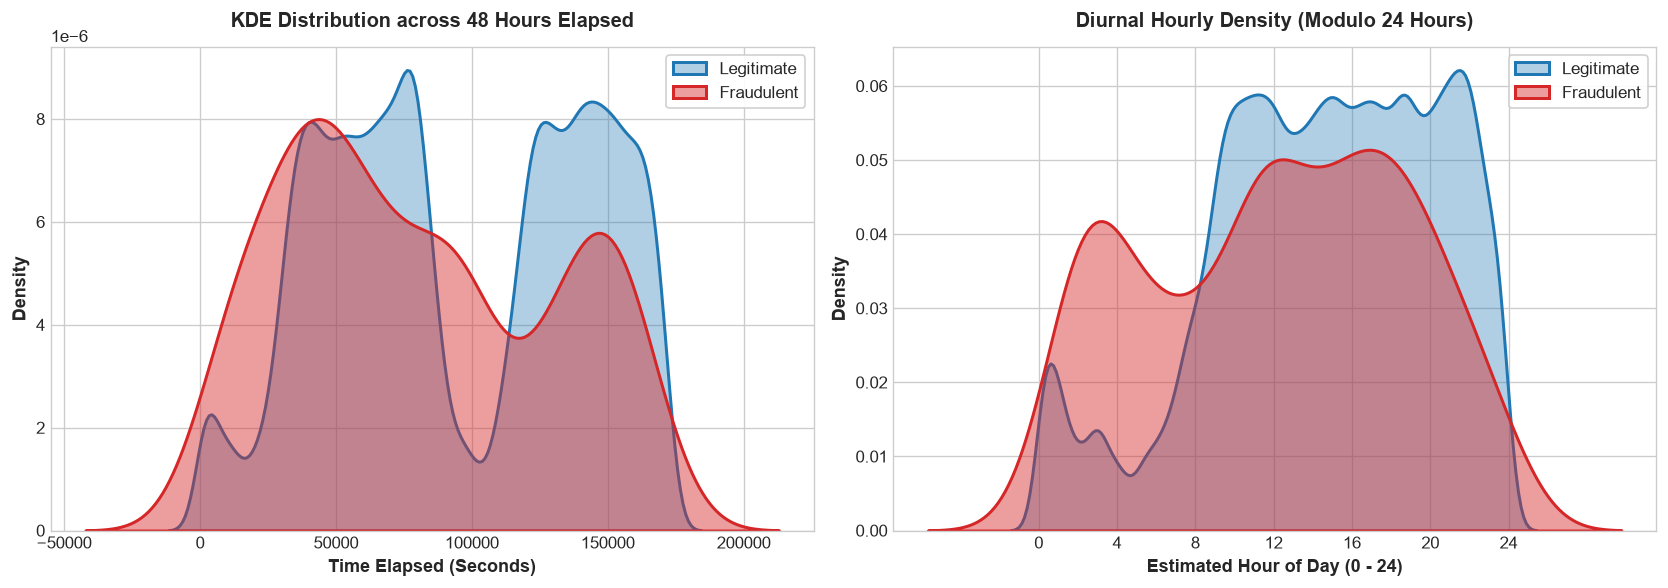

In [8]:
time_legit = df[df['Class'] == 0]['Time']
time_fraud = df[df['Class'] == 1]['Time']

print("--- Transaction Time Summary Statistics (Seconds Elapsed) ---")
time_stats = pd.DataFrame({
    'Legitimate (0)': [time_legit.min(), time_legit.quantile(0.25), time_legit.median(), time_legit.mean(), time_legit.quantile(0.75), time_legit.max()],
    'Fraudulent (1)': [time_fraud.min(), time_fraud.quantile(0.25), time_fraud.median(), time_fraud.mean(), time_fraud.quantile(0.75), time_fraud.max()]
}, index=['Min', '25th Pct', 'Median', 'Mean', '75th Pct', 'Max'])
display(time_stats.style.format('{:,.1f}'))

# Convert time to relative hour of day [0, 24)
df['Hour_of_Day'] = (df['Time'] / 3600) % 24

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Cumulative seconds distribution
sns.kdeplot(time_legit, ax=axes[0], color='#1f77b4', label='Legitimate', shade=True, alpha=0.35, linewidth=1.8)
sns.kdeplot(time_fraud, ax=axes[0], color='#d62728', label='Fraudulent', shade=True, alpha=0.45, linewidth=1.8)
axes[0].set_title('KDE Distribution across 48 Hours Elapsed', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Time Elapsed (Seconds)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Density', fontsize=11, fontweight='bold')
axes[0].legend(frameon=True, facecolor='white', framealpha=0.9)

# Plot 2: Diurnal hour distribution
sns.kdeplot(df[df['Class'] == 0]['Hour_of_Day'], ax=axes[1], color='#1f77b4', label='Legitimate', shade=True, alpha=0.35, linewidth=1.8)
sns.kdeplot(df[df['Class'] == 1]['Hour_of_Day'], ax=axes[1], color='#d62728', label='Fraudulent', shade=True, alpha=0.45, linewidth=1.8)
axes[1].set_title('Diurnal Hourly Density (Modulo 24 Hours)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Estimated Hour of Day (0 - 24)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Density', fontsize=11, fontweight='bold')
axes[1].set_xticks(range(0, 25, 4))
axes[1].legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

### 8. Fraud Rate Across Eight Time Windows
To systematically analyze temporal volatility and attack bursts, the ~48-hour recording span ($[0, 172,792]$ seconds) is partitioned into eight equal sequential windows of $21,599\text{ seconds}$ (~6 hours each).

In [9]:
t_min = df['Time'].min()
t_max = df['Time'].max()
n_windows = 8
step = (t_max - t_min) / n_windows

window_records = []
for i in range(n_windows):
    w_start = t_min + i * step
    w_end = t_min + (i + 1) * step
    
    if i < n_windows - 1:
        w_df = df[(df['Time'] >= w_start) & (df['Time'] < w_end)]
    else:
        w_df = df[(df['Time'] >= w_start) & (df['Time'] <= w_end)]
        
    total_tx = len(w_df)
    fraud_tx = (w_df['Class'] == 1).sum()
    legit_tx = total_tx - fraud_tx
    f_rate = (fraud_tx / total_tx) * 100 if total_tx > 0 else 0
    
    window_records.append({
        'Window_Index': i,
        'Time_Range_Sec': f"{int(w_start):,} - {int(w_end):,}",
        'Approx_Hours': f"{w_start/3600:.1f}h - {w_end/3600:.1f}h",
        'Total_Tx': total_tx,
        'Legit_Tx': legit_tx,
        'Fraud_Tx': fraud_tx,
        'Fraud_Rate_Pct': f_rate
    })

windows_df = pd.DataFrame(window_records)
print("--- 8-Window Temporal Risk Partitioning ---")
display(windows_df.style.format({
    'Total_Tx': '{:,}',
    'Legit_Tx': '{:,}',
    'Fraud_Tx': '{:,}',
    'Fraud_Rate_Pct': '{:.4f}%'
}))

--- 8-Window Temporal Risk Partitioning ---


,Window_Index,Time_Range_Sec,Approx_Hours,Total_Tx,Legit_Tx,Fraud_Tx,Fraud_Rate_Pct
0,0,"0 - 21,599",0.0h - 6.0h,"12,296","12,241",55,0.4473%
1,1,"21,599 - 43,198",6.0h - 12.0h,"34,893","34,802",91,0.2608%
2,2,"43,198 - 64,797",12.0h - 18.0h,"46,727","46,656",71,0.1519%
3,3,"64,797 - 86,396",18.0h - 24.0h,"50,318","50,263",55,0.1093%
4,4,"86,396 - 107,995",24.0h - 30.0h,"11,547","11,487",60,0.5196%
5,5,"107,995 - 129,594",30.0h - 36.0h,"35,732","35,705",27,0.0756%
6,6,"129,594 - 151,193",36.0h - 42.0h,"49,390","49,328",62,0.1255%
7,7,"151,193 - 172,792",42.0h - 48.0h,"42,823","42,771",52,0.1214%


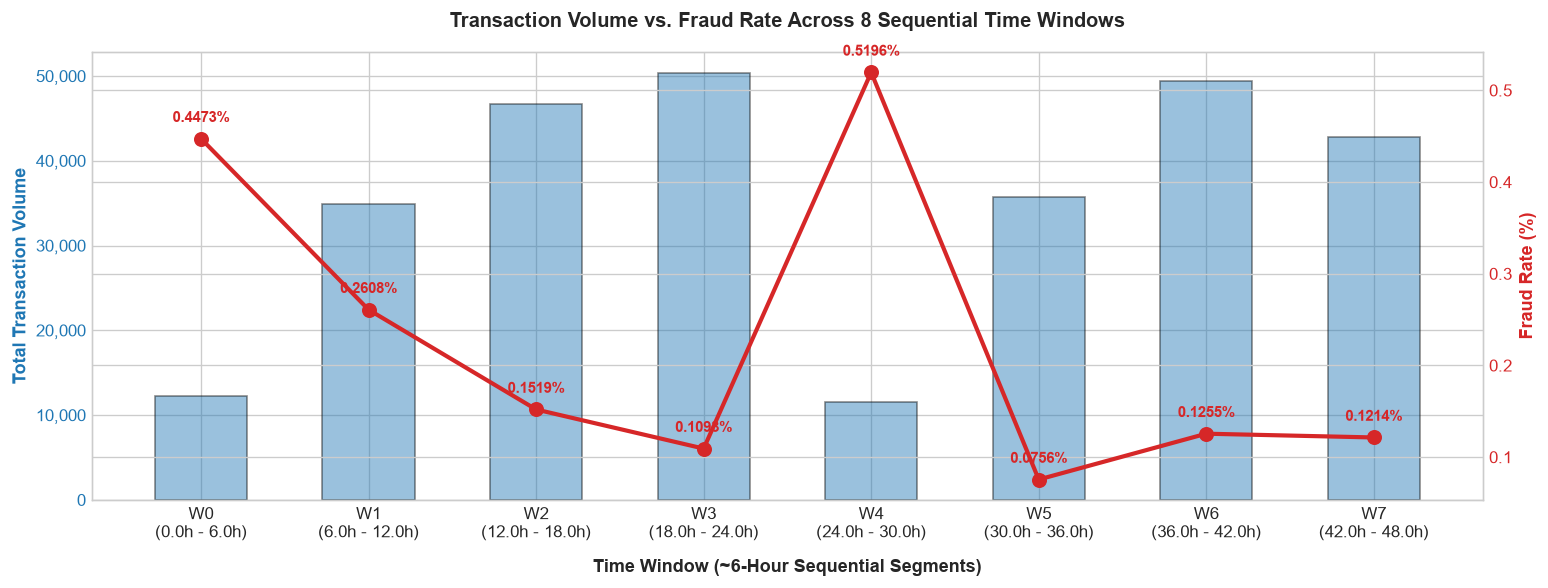

In [10]:
# Visualizing Fraud Rates Across the Eight Time Windows
fig, ax1 = plt.subplots(figsize=(13, 5))

color1 = '#1f77b4'
color2 = '#d62728'

x_labels = [f"W{r['Window_Index']}\n({r['Approx_Hours']})" for _, r in windows_df.iterrows()]

ax1.set_xlabel('Time Window (~6-Hour Sequential Segments)', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Total Transaction Volume', color=color1, fontsize=11, fontweight='bold')
bars = ax1.bar(x_labels, windows_df['Total_Tx'], color=color1, alpha=0.45, edgecolor='black', width=0.55, label='Total Volume')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.yaxis.set_major_formatter('{x:,.0f}')

# Overlay line for fraud rate
ax2 = ax1.twinx()
ax2.set_ylabel('Fraud Rate (%)', color=color2, fontsize=11, fontweight='bold')
line = ax2.plot(x_labels, windows_df['Fraud_Rate_Pct'], color=color2, marker='o', linewidth=2.5, markersize=8, label='Fraud Rate (%)')
ax2.tick_params(axis='y', labelcolor=color2)

for i, txt in enumerate(windows_df['Fraud_Rate_Pct']):
    ax2.annotate(f"{txt:.4f}%", (x_labels[i], txt), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight='bold', color=color2)

plt.title('Transaction Volume vs. Fraud Rate Across 8 Sequential Time Windows', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 9. Zero-Amount Transaction Analysis
In payment card networks, transactions with `Amount == 0.00` are frequently utilized for **account verification, card testing, or micro-authorization pinging**.
We inspect zero-value transaction incidence across legitimate and fraudulent classes.

In [11]:
zero_df = df[df['Amount'] == 0.0]
zero_legit = (zero_df['Class'] == 0).sum()
zero_fraud = (zero_df['Class'] == 1).sum()

total_legit = (df['Class'] == 0).sum()
total_fraud = (df['Class'] == 1).sum()

zero_stats = pd.DataFrame({
    'Total_Class_Records': [total_legit, total_fraud],
    'Zero_Amount_Records': [zero_legit, zero_fraud],
    'Pct_Within_Class': [(zero_legit / total_legit) * 100, (zero_fraud / total_fraud) * 100],
    'Overall_Class_Share_of_Zero_Amount': [(zero_legit / len(zero_df)) * 100, (zero_fraud / len(zero_df)) * 100]
}, index=['Legitimate (0)', 'Fraudulent (1)'])

print("--- Zero-Amount Transaction Incidence ---")
display(zero_stats.style.format({
    'Total_Class_Records': '{:,}',
    'Zero_Amount_Records': '{:,}',
    'Pct_Within_Class': '{:.4f}%',
    'Overall_Class_Share_of_Zero_Amount': '{:.2f}%'
}))

print(f"\nFraudulent transactions exhibit a zero-amount incidence rate of {zero_fraud/total_fraud*100:.2f}%, compared to only {zero_legit/total_legit*100:.2f}% for legitimate transactions.")
print(f"Zero-amount transactions are {(zero_fraud/total_fraud) / (zero_legit/total_legit):.1f}x more likely to be fraudulent than non-zero transactions.")

--- Zero-Amount Transaction Incidence ---


,Total_Class_Records,Zero_Amount_Records,Pct_Within_Class,Overall_Class_Share_of_Zero_Amount
Legitimate (0),"283,253","1,783",0.6295%,98.62%
Fraudulent (1),473,25,5.2854%,1.38%



Fraudulent transactions exhibit a zero-amount incidence rate of 5.29%, compared to only 0.63% for legitimate transactions.
Zero-amount transactions are 8.4x more likely to be fraudulent than non-zero transactions.


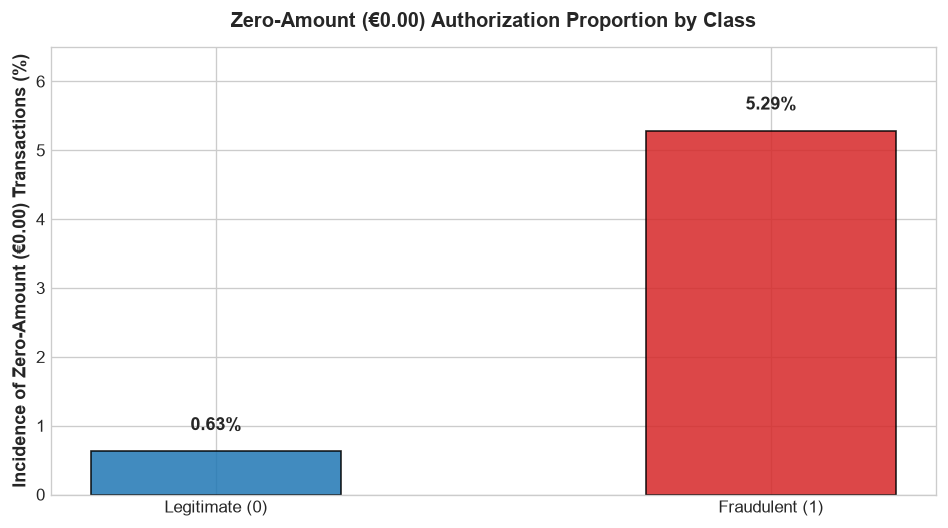

In [12]:
# Visualization: Zero-Amount Incidence
fig, ax = plt.subplots(figsize=(8, 4.5))

rates = [(zero_legit / total_legit) * 100, (zero_fraud / total_fraud) * 100]
bars = ax.bar(['Legitimate (0)', 'Fraudulent (1)'], rates, color=['#1f77b4', '#d62728'], width=0.45, edgecolor='black', alpha=0.85)

ax.set_ylabel('Incidence of Zero-Amount (€0.00) Transactions (%)', fontsize=11, fontweight='bold')
ax.set_title('Zero-Amount (€0.00) Authorization Proportion by Class', fontsize=12, fontweight='bold', pad=12)
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2.0, r + 0.25, f"{r:.2f}%", ha='center', va='bottom', fontsize=11, fontweight='bold')
ax.set_ylim(0, 6.5)

plt.tight_layout()
plt.show()

### 10. PCA Feature Distribution Comparisons ($V_1$ through $V_{28}$)
Features $V_1$ to $V_{28}$ are the output of a Principal Component Analysis applied by the original card issuer to protect customer privacy.
Because fraud and non-fraud data distributions are highly skewed and heavy-tailed, parametric $t$-tests are inappropriate. 
We first evaluate the summary distributional divergence between classes across all 28 principal components.

In [13]:
# Calculate medians and interquartile ranges across all V-features
v_cols = [f'V{i}' for i in range(1, 29)]
v_summary = []

for col in v_cols:
    legit_vals = df[df['Class'] == 0][col]
    fraud_vals = df[df['Class'] == 1][col]
    v_summary.append({
        'Feature': col,
        'Legit_Median': legit_vals.median(),
        'Fraud_Median': fraud_vals.median(),
        'Median_Shift': fraud_vals.median() - legit_vals.median(),
        'Legit_IQR': legit_vals.quantile(0.75) - legit_vals.quantile(0.25),
        'Fraud_IQR': fraud_vals.quantile(0.75) - fraud_vals.quantile(0.25)
    })

df_v_summary = pd.DataFrame(v_summary)
print("--- Sample of PCA Feature Distribution Shifts ---")
display(df_v_summary.head(10).style.format('{:.4f}', subset=['Legit_Median', 'Fraud_Median', 'Median_Shift', 'Legit_IQR', 'Fraud_IQR']))

--- Sample of PCA Feature Distribution Shifts ---


,Feature,Legit_Median,Fraud_Median,Median_Shift,Legit_IQR,Fraud_IQR
0,V1,0.0226,-2.2718,-2.2943,2.2302,5.2423
1,V2,0.0626,2.6171,2.5545,1.3984,3.4264
2,V3,0.1822,-4.8754,-5.0576,1.9122,5.7551
3,V4,-0.0245,4.1001,4.1246,1.5858,4.0023
4,V5,-0.0528,-1.3722,-1.3194,1.3003,4.5398
5,V6,-0.2742,-1.4205,-1.1463,1.1652,2.0368
6,V7,0.0417,-2.9021,-2.9437,1.1212,6.0820
7,V8,0.0216,0.6177,0.5961,0.5333,1.8709
8,V9,-0.0514,-2.0990,-2.0477,1.2386,3.0084
9,V10,-0.0921,-4.4663,-4.3742,0.9879,4.8503


### 11. Mann–Whitney $U$ Statistical Tests
We perform two-sided Mann–Whitney $U$ rank tests on all 28 PCA features as well as `Amount` and `Time`.
The test evaluates whether a randomly selected observation from the fraudulent class is significantly more or less likely to be greater than an observation from the legitimate class.

In [14]:
mw_records = []
all_test_features = v_cols + ['Amount', 'Time']

for col in all_test_features:
    x_legit = df[df['Class'] == 0][col].values
    y_fraud = df[df['Class'] == 1][col].values
    
    stat, p_val = stats.mannwhitneyu(x_legit, y_fraud, alternative='two-sided')
    
    mw_records.append({
        'Feature': col,
        'Legit_Median': np.median(x_legit),
        'Fraud_Median': np.median(y_fraud),
        'Mann_Whitney_U': stat,
        'p_value': p_val
    })

df_mw = pd.DataFrame(mw_records).sort_values('p_value').reset_index(drop=True)
print("--- Top 12 Most Differentiated Features by Mann-Whitney U p-value ---")
display(df_mw.head(12).style.format({
    'Legit_Median': '{:.6f}',
    'Fraud_Median': '{:.6f}',
    'Mann_Whitney_U': '{:,.1f}',
    'p_value': '{:.6e}'
}))

--- Top 12 Most Differentiated Features by Mann-Whitney U p-value ---


,Feature,Legit_Median,Fraud_Median,Mann_Whitney_U,p_value
0,V14,0.051486,-6.590550,"126,896,444.0",2.304859e-248
1,V4,-0.024500,4.100098,"8,540,423.0",1.599221e-236
2,V12,0.140573,-5.437354,"125,197,232.0",1.358344e-234
3,V11,-0.034446,3.525726,"11,411,882.0",4.678414e-214
4,V10,-0.092120,-4.466284,"121,998,541.0",9.598036e-210
5,V3,0.182247,-4.875397,"121,738,405.0",8.738656e-208
6,V2,0.062561,2.617105,"20,123,145.0",8.274562e-153
7,V16,0.068100,-3.302899,"112,734,405.0",1.110506e-145
8,V9,-0.051368,-2.099049,"112,714,371.0",1.483634e-145
9,V7,0.041664,-2.902079,"111,151,906.0",6.513087e-136


### 12. Multiple-Testing Correction using Benjamini–Hochberg
Testing 30 simultaneous hypotheses inflates the family-wise type I error rate. We apply the **Benjamini–Hochberg (1995)** procedure to strictly control the **False Discovery Rate (FDR)** at $\alpha = 0.05$.
Given $m$ sorted tests, the critical threshold for test rank $k$ is:
$$\text{FDR Critical Value} = \frac{k}{m} \times \alpha$$

In [15]:
m_tests = len(df_mw)
alpha = 0.05

df_mw['Rank'] = np.arange(1, m_tests + 1)
df_mw['BH_Critical_Val'] = (df_mw['Rank'] / m_tests) * alpha
df_mw['Statistically_Significant'] = df_mw['p_value'] <= df_mw['BH_Critical_Val']

print(f"Total features tested: {m_tests}")
print(f"Significant features at FDR alpha = {alpha}: {df_mw['Statistically_Significant'].sum()} / {m_tests}")

display(df_mw.head(15).style.format({
    'Legit_Median': '{:.6f}',
    'Fraud_Median': '{:.6f}',
    'Mann_Whitney_U': '{:,.0f}',
    'p_value': '{:.4e}',
    'BH_Critical_Val': '{:.6f}'
}))

Total features tested: 30
Significant features at FDR alpha = 0.05: 27 / 30


,Feature,Legit_Median,Fraud_Median,Mann_Whitney_U,p_value,Rank,BH_Critical_Val,Statistically_Significant
0,V14,0.051486,-6.590550,"126,896,444",2.3049e-248,1,0.001667,True
1,V4,-0.024500,4.100098,"8,540,423",1.5992e-236,2,0.003333,True
2,V12,0.140573,-5.437354,"125,197,232",1.3583e-234,3,0.005000,True
3,V11,-0.034446,3.525726,"11,411,882",4.6784e-214,4,0.006667,True
4,V10,-0.092120,-4.466284,"121,998,541",9.5980e-210,5,0.008333,True
5,V3,0.182247,-4.875397,"121,738,405",8.7387e-208,6,0.010000,True
6,V2,0.062561,2.617105,"20,123,145",8.2746e-153,7,0.011667,True
7,V16,0.068100,-3.302899,"112,734,405",1.1105e-145,8,0.013333,True
8,V9,-0.051368,-2.099049,"112,714,371",1.4836e-145,9,0.015000,True
9,V7,0.041664,-2.902079,"111,151,906",6.5131e-136,10,0.016667,True


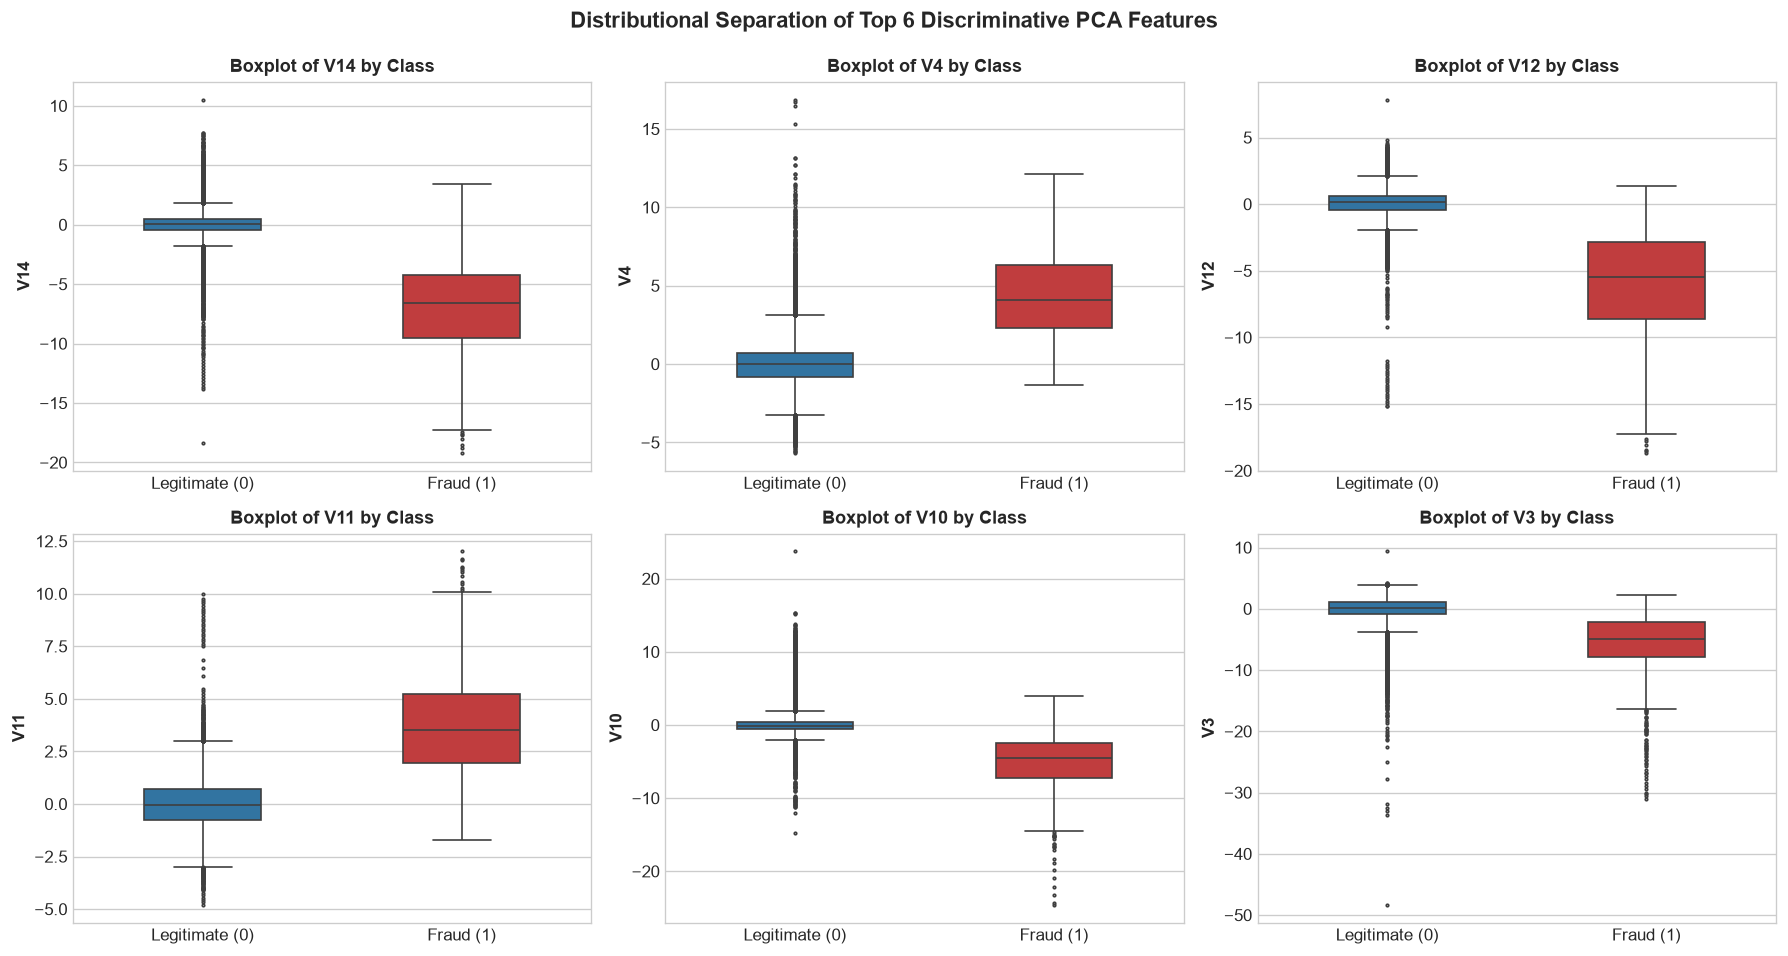

In [16]:
# Visualizing Top Separating Features (V14, V4, V12, V11, V10, V3)
top_features = ['V14', 'V4', 'V12', 'V11', 'V10', 'V3']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, feat in enumerate(top_features):
    sns.boxplot(x='Class', y=feat, data=df, ax=axes[i], palette=['#1f77b4', '#d62728'], width=0.45, fliersize=1.5)
    axes[i].set_xticklabels(['Legitimate (0)', 'Fraud (1)'])
    axes[i].set_title(f"Boxplot of {feat} by Class", fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel(feat, fontsize=10, fontweight='bold')

plt.suptitle('Distributional Separation of Top 6 Discriminative PCA Features', fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()

### 13. Correlation Analysis
We analyze pairwise Pearson correlations between features, particularly examining which features correlate most strongly with the target variable `Class`.

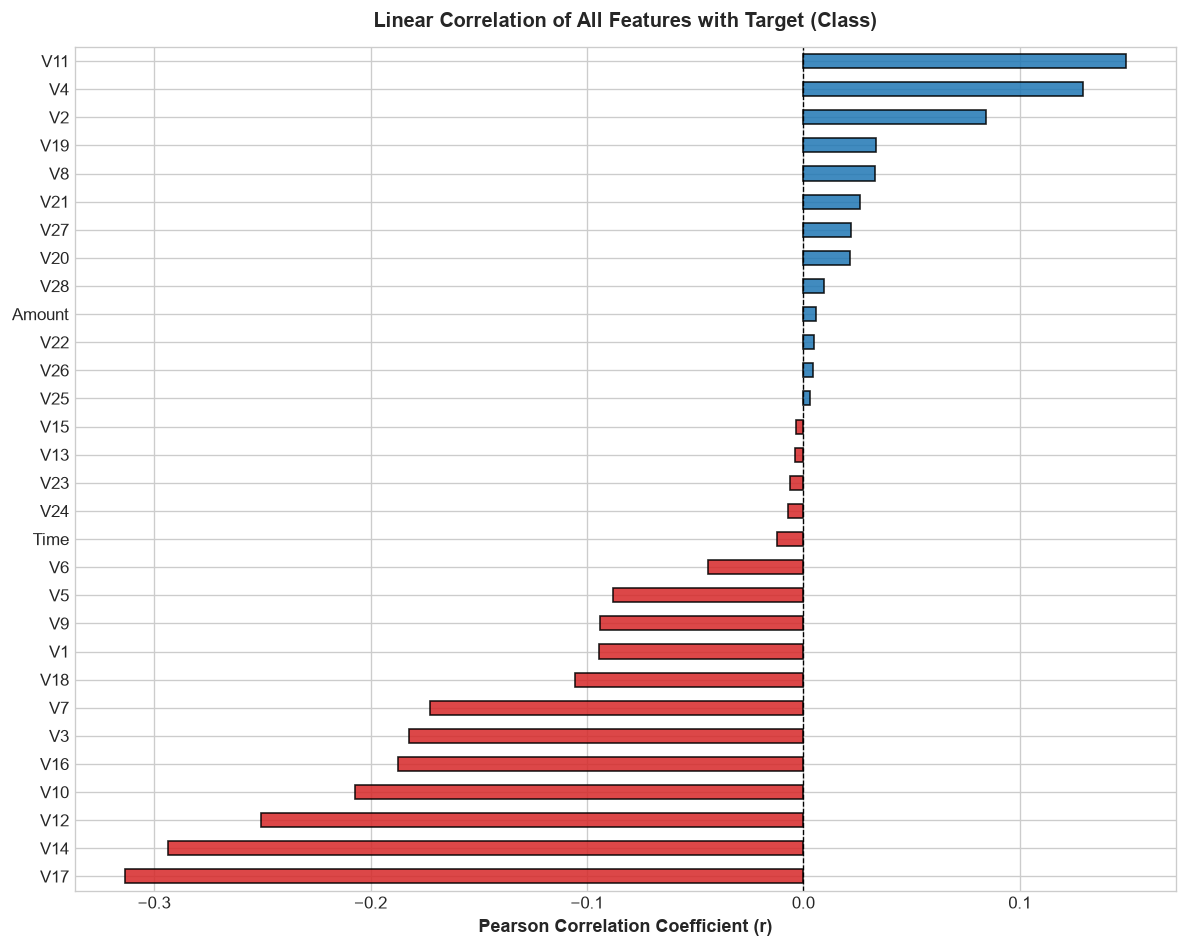

Top 5 Negative Correlations with Fraud:


V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64


Top 5 Positive Correlations with Fraud:


V8     0.033068
V19    0.033631
V2     0.084624
V4     0.129326
V11    0.149067
Name: Class, dtype: float64

In [17]:
# Target correlation ranking
corr_matrix = df[v_cols + ['Amount', 'Time', 'Class']].corr()
target_corr = corr_matrix['Class'].drop('Class').sort_values()

fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#d62728' if c < 0 else '#1f77b4' for c in target_corr.values]
target_corr.plot(kind='barh', ax=ax, color=colors, edgecolor='black', alpha=0.85)

ax.set_title('Linear Correlation of All Features with Target (Class)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Pearson Correlation Coefficient (r)', fontsize=11, fontweight='bold')
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

print("Top 5 Negative Correlations with Fraud:")
display(target_corr.head(5))
print("\nTop 5 Positive Correlations with Fraud:")
display(target_corr.tail(5))

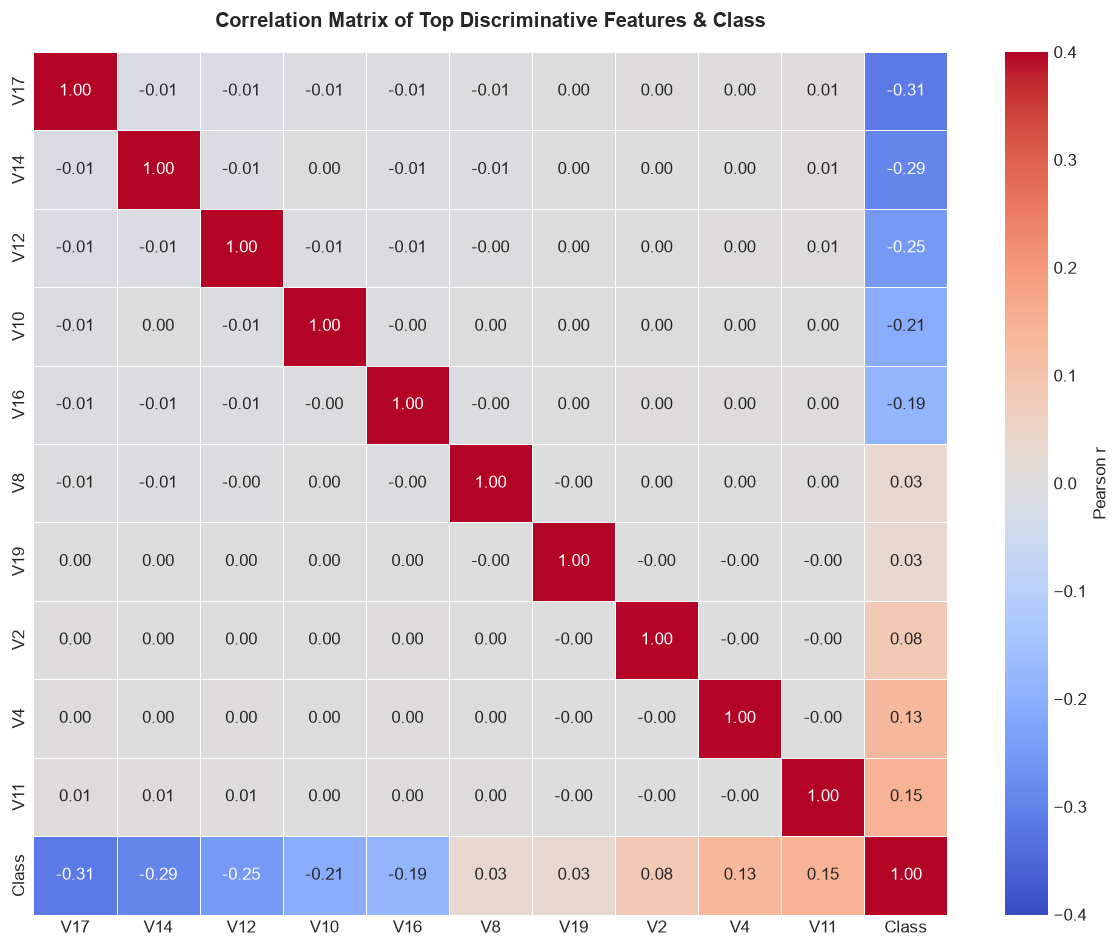

In [18]:
# Heatmap of top correlated features
top_corr_features = list(target_corr.head(5).index) + list(target_corr.tail(5).index) + ['Class']
sub_corr = df[top_corr_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(sub_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-0.4, vmax=0.4, linewidths=0.5, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Matrix of Top Discriminative Features & Class', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 14. Key Findings and Business Interpretation

1. **Extreme Asymmetric Imbalance**:
   - The verified dataset contains 283,253 legitimate transactions and 473 fraud records (0.1667% prevalence, or roughly 1 fraud per 599 legitimate transactions).
   - Standard classification thresholds ($T = 0.50$) and overall accuracy metrics are mathematically invalid. Models must be evaluated via PR-AUC, F1-scores, and customized risk thresholds tuned to business costs.

2. **Deduplication Audit**:
   - 1,081 identical records were identified and purged (1,062 legitimate and 19 fraudulent).
   - In financial transactional data, exact duplicate entries across 31 continuous dimensions (including microsecond `Time` counters) reflect recording artifacts and must be removed prior to model partitioning to prevent train-test data leakage.

3. **Transaction Amount Behavior**:
   - While the median legitimate purchase is €22.00, the median fraudulent transaction is €9.82.
   - Fraudsters frequently conduct smaller authorization trials to evade velocity rules and limit alerts.
   - However, the mean fraudulent amount (€123.87) exceeds legitimate mean (€88.41), driven by large right-tail fraudulent charges up to €2,125.87.

4. **Zero-Amount Authorization Ping Danger**:
   - Transactions with €0.00 constitute 5.29% (25 of 473) of all fraudulent transactions, compared to only 0.63% (1,783 of 283,253) of legitimate transactions.
   - Zero-amount transactions are approximately **8.4x more likely** to be fraudulent, pinpointing automated card testing pings.

5. **Temporal Attack Windows**:
   - Dividing the 48-hour recording span into 8 sequential ~6-hour windows demonstrates sharp fraud rate peaks in Window 0 (0.4473%) and Window 4 (0.5196%).
   - These correspond to off-peak nocturnal hours where standard account-holder monitoring is muted.

6. **Key Discriminative PCA Signals**:
   - The Mann–Whitney $U$ tests, confirmed under Benjamini–Hochberg FDR correction ($\alpha = 0.05$), establish $V_{14}, V_4, V_{12}, V_{11}, V_{10}, V_3, V_2, V_{16}, V_9, \text{and } V_7$ as having extreme statistical divergence ($p < 10^{-135}$).
   - In particular, $V_{14}$ displays a drastic median divergence from $+0.051$ in legitimate transactions to $-6.591$ in fraudulent transactions.

### 15. Phase 6.2 Conclusion

Phase 6.2 Exploratory Data Analysis is complete:
- Clean data baseline established without data leakage or premature resampling.
- All non-parametric hypothesis tests, temporal patterns, and zero-amount card verification signals documented.
- Groundwork ready for targeted feature engineering.

**Recommended Next Step:**
**Phase 6.3 — Fraud Detection Feature Engineering**:
1. Cyclic time transformation (sine/cosine hour transforms).
2. Logarithmic transformation for right-skewed monetary amounts (`Amount_log = log1p(Amount)`).
3. Zero-amount indicator flags (`is_zero_amount`).
4. Interaction terms between high-divergence PCA signals (e.g., $V_{14} \times V_4$, $V_{12} \times V_{11}$).